**CHAPTER 8**
**TOPIC MODELING PADA DATA KOMENTAR TIKTOK**

Nama: Tabrizzi Aqlia
NIM: 25031554008

Pada Exercise 8 ini, saya menerapkan topic modeling dengan metode Latent Dirichlet Allocation (LDA) pada komentar TikTok hasil preprocessing Chapter 4 (kolom prepro). Hasil yang dianalisis meliputi kata kunci tiap topik, persentase topik pada setiap komentar, coherence score, dan visualisasi topik.

**Install & import**

In [1]:
!pip install -q gensim pyLDAvis

import warnings
warnings.filterwarnings(action='ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

**Ambil data hasil Chapter 4**

Ambil data

In [2]:
try:
    df = hasil_tiktok.copy()
except NameError:
    for path in ['hasil_tiktok.csv', 'sample_data/hasil_tiktok.csv']:
        if os.path.exists(path):
            df = pd.read_csv(path)
            print("Data dibaca dari:", path)
            break
    else:
        raise FileNotFoundError("hasil_tiktok.csv tidak ditemukan, upload dulu ke Colab")

df = df.dropna(subset=['prepro']).copy()
df['prepro'] = df['prepro'].astype(str).str.strip()
df = df[df['prepro'] != ''].reset_index(drop=True)

docs = df['prepro']
print("Jumlah komentar yang dipakai:", len(df))
df[['text_original', 'prepro']].head(1265)

Data dibaca dari: sample_data/hasil_tiktok.csv
Jumlah komentar yang dipakai: 1265


,text_original,prepro
0,AGUSTUS JAHAT.,agustus jahat
1,monyet nya gimana ya,monyet nya gimana
2,kondisi hewannya gimana termasuk ini?,kondisi hewan gimana masuk
3,"yaallah kasian banget hewan hewan disana, leka...",yaallah kasi banget hewan hewan sana lekas pul...
4,semoga cepat hujan ya kalimantan,moga cepat hujan kalimantan
...,...,...
1260,udah kaya di ajab allah gak sih,udah kaya ajab allah gak sih
1261,gua kena asap karna gua Kalimantan Barat,gua kena asap karna gua kalimantan barat
1262,di bakar,bakar
1263,yallah,yallah


**1. Persiapan Data: Tokenisasi, Dictionary, dan Corpus**

Teks prepro dipecah menjadi kata (token), lalu dibuat dictionary (daftar kata unik) dan corpus (representasi bag of words tiap komentar). Kata yang muncul di kurang dari 3 komentar dan kata yang muncul di lebih dari 50% komentar dibuang agar topik tidak didominasi kata yang terlalu langka atau terlalu umum.

Dictionary dan corpus

In [3]:
sentences = [t.split() for t in docs]

dictionary = corpora.Dictionary(sentences)
print("Jumlah kata unik sebelum filter:", len(dictionary))

dictionary.filter_extremes(no_below=3, no_above=0.5)
print("Jumlah kata unik setelah filter:", len(dictionary))

corpus = [dictionary.doc2bow(doc) for doc in sentences]
kosong = sum(1 for c in corpus if not c)
print("Komentar yang kosong setelah filter:", kosong)

Jumlah kata unik sebelum filter: 3000
Jumlah kata unik setelah filter: 805
Komentar yang kosong setelah filter: 59


**2. Menentukan Jumlah Topik**

LDA dijalankan untuk k = 2 sampai 7, lalu dibandingkan nilai coherence (c_v). Semakin tinggi nilainya (0 sampai 1), semakin bermakna topik yang terbentuk.

Coherence untuk beberapa nilai k

,Jumlah topik (k),Coherence c_v
0,2,0.4251
1,3,0.4055
2,4,0.4170
3,5,0.3663
4,6,0.3747
5,7,0.3580


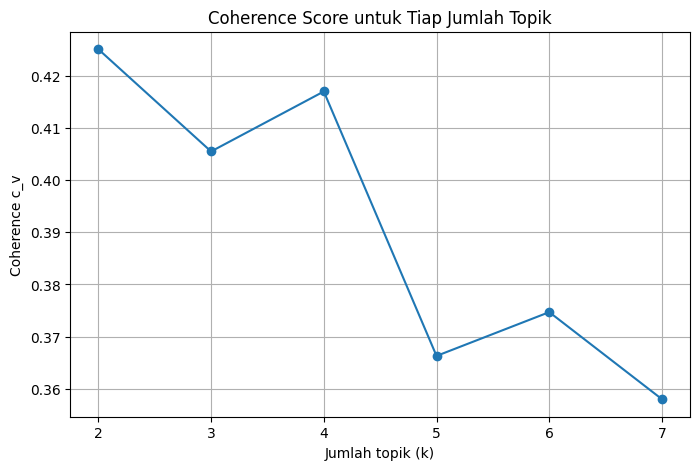

In [4]:
hasil_k = []
for k in range(2, 8):
    m = LdaModel(
        corpus=corpus, id2word=dictionary, num_topics=k,
        iterations=400, passes=10, alpha='auto', eta='auto', random_state=42
    )
    cv = CoherenceModel(model=m, texts=sentences, dictionary=dictionary, coherence='c_v').get_coherence()
    hasil_k.append({'Jumlah topik (k)': k, 'Coherence c_v': round(cv, 4)})

tabel_k = pd.DataFrame(hasil_k)
display(tabel_k)

plt.figure(figsize=(8, 5))
plt.plot(tabel_k['Jumlah topik (k)'], tabel_k['Coherence c_v'], marker='o')
plt.title('Coherence Score untuk Tiap Jumlah Topik')
plt.xlabel('Jumlah topik (k)')
plt.ylabel('Coherence c_v')
plt.grid()
plt.show()

**3. Model LDA Final**

Jumlah topik ditetapkan 3 mengikuti contoh pada materi. Nilai coherence k = 3 (0,4055) tidak jauh dari nilai tertinggi pada k = 2 (0,4251) dan k = 4 (0,4170), sedangkan tiga topik lebih kaya untuk ditafsirkan daripada dua.

Latih LDA final

In [6]:
num_topics = 3

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    iterations=5000,
    passes=10,
    alpha='auto',
    eta='auto',
    random_state=42
)

for idx, topic in lda_model.print_topics(-1):
    print(f"Topik {idx}: {topic}\n")

Topik 0: 0.020*"yg" + 0.018*"nya" + 0.017*"bakar" + 0.016*"perintah" + 0.015*"hujan" + 0.013*"turun" + 0.013*"ga" + 0.012*"allah" + 0.012*"aja" + 0.012*"kalimantan"

Topik 1: 0.029*"yg" + 0.028*"bakar" + 0.019*"gak" + 0.017*"kalimantan" + 0.014*"udah" + 0.011*"aku" + 0.011*"nya" + 0.011*"mau" + 0.010*"orang" + 0.009*"aja"

Topik 2: 0.026*"allah" + 0.025*"yg" + 0.024*"bakar" + 0.022*"kak" + 0.015*"kalimantan" + 0.014*"aku" + 0.013*"asap" + 0.012*"moga" + 0.011*"semua" + 0.011*"hutan"



**Kata kunci tiap topik**

Tabel kata kunci

In [7]:
kata_topik = pd.DataFrame({
    f'Topik {i}': [f"{w} ({p:.3f})" for w, p in lda_model.show_topic(i, topn=10)]
    for i in range(num_topics)
})
kata_topik

,Topik 0,Topik 1,Topik 2
0,yg (0.020),yg (0.029),allah (0.026)
1,nya (0.018),bakar (0.028),yg (0.025)
2,bakar (0.017),gak (0.019),bakar (0.024)
3,perintah (0.016),kalimantan (0.017),kak (0.022)
4,hujan (0.015),udah (0.014),kalimantan (0.015)
5,turun (0.013),aku (0.011),aku (0.014)
6,ga (0.013),nya (0.011),asap (0.013)
7,allah (0.012),mau (0.011),moga (0.012)
8,aja (0.012),orang (0.010),semua (0.011)
9,kalimantan (0.012),aja (0.009),hutan (0.011)


**Topik dominan tiap komentar**

Topik dominan

In [8]:
dominan, peluang = [], []
for bow in corpus:
    dist = lda_model.get_document_topics(bow, minimum_probability=0)
    t, p = max(dist, key=lambda x: x[1])
    dominan.append(t)
    peluang.append(p)

df['Topik_dominan'] = dominan
df['Peluang_topik'] = np.round(peluang, 4)

print("Jumlah komentar per topik dominan:")
display(df['Topik_dominan'].value_counts().sort_index().to_frame('Jumlah komentar'))

print("Persentase komentar per topik (%):")
display((df['Topik_dominan'].value_counts(normalize=True).sort_index() * 100).round(2).to_frame('Persentase'))

Jumlah komentar per topik dominan:


,Jumlah komentar
Topik_dominan,
0,389
1,481
2,395


Persentase komentar per topik (%):


,Persentase
Topik_dominan,
0,30.75
1,38.02
2,31.23


**Contoh komentar paling kuat tiap topik**

Contoh komentar

In [9]:
pd.set_option('display.max_colwidth', 150)

for t in range(num_topics):
    print(f"\n=== Topik {t} (3 komentar dengan peluang tertinggi) ===")
    contoh = df[df['Topik_dominan'] == t].sort_values('Peluang_topik', ascending=False).head(3)
    display(contoh[['text_original', 'Peluang_topik']])


=== Topik 0 (3 komentar dengan peluang tertinggi) ===


,text_original,Peluang_topik
749,"Dibawah tanah Kalimantan itu gambut dek, bukan tanah liat. tanah liat itu biasanya lempung atau lanau, beda ya dek ya. Ditambah lagi api tidak aka...",0.9960
378,buat apa beli alutsista buang anggaran aja bukan begitu nona ingat GK banyak yg bilang buat apa beli itu buang duit mana bekas lagi terus ingat ju...,0.9948
715,iya kak. ngerti yg lain juga. maksudnya kondisi lagi begini apa pantes bagi bagu jabatan dulu? ibarat rumah lu lagi kebakaran lu malah party. duh ...,0.9930



=== Topik 1 (3 komentar dengan peluang tertinggi) ===


,text_original,Peluang_topik
1154,"saya udah bener"" muak banget,walau saya tidak hidup dikalimantan tp kasian sedih ikut ngerasa sakit gimana dengan bayi"" /anak"" disana, tiap hari m...",0.9946
896,"Sama, di bromo, di kawa ijen, dibatu gunung2 juga pada ada yang kebakaran karena cuaca siang panas, dan menjelang malam musim dingin... Dari dulu ...",0.9944
459,"Tingkat bencana ini skalanya nasional, bahkan dampaknya menyebar sampai ke negara lain. Oke, bukan presiden yg salah, tp tugas dia menetapkan skal...",0.9943



=== Topik 2 (3 komentar dengan peluang tertinggi) ===


,text_original,Peluang_topik
194,"di tempatku lagi ada pengerukan tanah buat jalan, pas aku liat liat pantesan kalo kebakaran hutan tuh lama padamnya malah bisa ke ulang tanpa ada ...",0.9938
173,"Buat yang belum paham kebakaran gambut, seperti inilah gambaran susahnya memadamkan kalau terjadi kebakaran. Api bukan hanya membakar di permukaan...",0.9933
87,"aku tinggal dikalteng asap tebel banget sedih ga bisa liat orang hutan sama juga ga bisa sekolah sama temen,selalu setiap pagi yang kulihat asap b...",0.9931


**Persentase topik pada beberapa komentar**

Distribusi topik per komentar

In [10]:
for i in range(5):
    print(f"Komentar {i}: {df.loc[i, 'text_original'][:100]}")
    print("   ", [(t, round(float(p), 3)) for t, p in lda_model.get_document_topics(corpus[i], minimum_probability=0)])

Komentar 0: AGUSTUS JAHAT.
    [(0, 0.054), (1, 0.893), (2, 0.053)]
Komentar 1: monyet nya gimana ya
    [(0, 0.921), (1, 0.041), (2, 0.038)]
Komentar 2: kondisi hewannya gimana termasuk ini?
    [(0, 0.029), (1, 0.032), (2, 0.939)]
Komentar 3: yaallah kasian banget hewan hewan disana, lekas pulih kalimantanku 🥺
    [(0, 0.014), (1, 0.973), (2, 0.014)]
Komentar 4: semoga cepat hujan ya kalimantan
    [(0, 0.939), (1, 0.032), (2, 0.029)]


**Coherence score model final**

Coherence final

In [11]:
coherence = CoherenceModel(model=lda_model, texts=sentences, dictionary=dictionary, coherence='c_v')
print("Coherence score (c_v):", round(coherence.get_coherence(), 4))

Coherence score (c_v): 0.4055


**4. Visualisasi Topik (pyLDAvis)**

- Ukuran lingkaran menunjukkan proporsi tiap topik.
- Jarak antar lingkaran menunjukkan seberapa berbeda antar topik (semakin jauh, semakin berbeda).
- Panel kanan menampilkan kata-kata paling penting pada tiap topik.

pyLDAvis

In [12]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, corpus, dictionary)
pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**ANALISIS HASIL TOPIC MODELING**

1. **Persiapan data.** Dari 3000 kata unik, setelah filter (kata muncul di minimal 3 komentar dan maksimal 50% komentar) tersisa 805 kata. Sebanyak 59 komentar menjadi kosong setelah filter karena hanya berisi kata langka.

2. **Jumlah topik.** Coherence (c_v) untuk k = 2 sampai 7 berkisar 0,3580 sampai 0,4251, dengan nilai tertinggi pada k = 2 (0,4251), diikuti k = 4 (0,4170) dan k = 3 (0,4055). Selisihnya kecil, sehingga dipilih k = 3 mengikuti materi agar topik lebih mudah ditafsirkan. Coherence cenderung menurun saat jumlah topik bertambah.

3. **Topik yang terbentuk.** Topik 0 memuat kata perintah (pemerintah), hujan, turun, nya, dan allah; contoh komentar paling kuat membahas lahan gambut, anggaran pertahanan, dan kritik terhadap pejabat, sehingga cenderung bertema kritik kebijakan dan penjelasan penyebab kebakaran. Topik 1 memuat kata gak, udah, aku, mau, dan orang; contoh komentarnya berisi rasa sedih, empati, dan opini tentang skala bencana, sehingga cenderung bertema ungkapan perasaan dan opini pribadi. Topik 2 memuat kata allah, kak, asap, moga, dan hutan; contoh komentarnya membahas sulitnya memadamkan api gambut dan dampak asap tebal pada warga Kalimantan, sehingga cenderung bertema dampak asap dan doa. Penamaan tema ini bersifat tafsiran awal karena kata kunci antar topik banyak yang sama.

4. **Sebaran topik.** Topik 1 paling banyak menjadi topik dominan (481 komentar, 38,02%), disusul Topik 2 (395 komentar, 31,23%) dan Topik 0 (389 komentar, 30,75%). Sebaran yang relatif merata menunjukkan tidak ada topik yang sangat dominan. Perlu dicatat, 59 komentar kosong ikut terhitung dalam sebaran ini karena model tetap menetapkan topik dominan untuknya.

5. **Persentase topik pada komentar.** Komentar pendek memiliki peluang topik yang tinggi pada satu topik, misalnya komentar "yaallah kasian banget hewan hewan disana, lekas pulih kalimantanku" memiliki peluang 0,973 pada Topik 1 dan "semoga cepat hujan ya kalimantan" memiliki peluang 0,939 pada Topik 0. Namun, peluang tinggi pada komentar pendek tidak selalu berarti topik tersebut sangat bermakna, karena komentar hanya memuat sedikit kata.

6. **Coherence model final.** Coherence k = 3 sebesar 0,4055, tergolong sedang. Hal ini wajar karena komentar TikTok pendek dan bahasa informal, serta kata umum seperti yg, nya, bakar, dan kalimantan muncul di ketiga topik sehingga topik saling tumpang tindih.

7. **Visualisasi (pyLDAvis).** Pada pyLDAvis, lingkaran topik [saling terpisah / sebagian saling tumpang tindih], yang menunjukkan topik [berbeda jelas / memiliki kata yang mirip]. Hal ini sejalan dengan tabel kata kunci, di mana kata yg dan bakar muncul pada ketiga topik.

8. **Kesimpulan.** Komentar TikTok tentang kebakaran Kalimantan membahas kritik terhadap kebijakan dan pemerintah, ungkapan empati dan opini pribadi, serta dampak asap dan doa. Keterbatasannya adalah komentar pendek dan bahasa informal sehingga topik masih memuat kata umum dan saling tumpang tindih. Untuk perbaikan, kata informal seperti yg, nya, gak, dan aja dapat ditambahkan sebagai stopword tambahan pada tahap preprocessing.